In [3]:
library(tidyverse)

#Import dataset
wine <- read_csv("winequality-red.csv")

head(wine)

Rows: 1599 Columns: 12
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (12): fixed acidity, volatile acidity, citric acid, residual sugar, chlo...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
7.4,0.70,0.00,1.9,0.076,11,34,0.9978,3.51,0.56,9.4,5
7.8,0.88,0.00,2.6,0.098,25,67,0.9968,3.20,0.68,9.8,5
7.8,0.76,0.04,2.3,0.092,15,54,0.9970,3.26,0.65,9.8,5
11.2,0.28,0.56,1.9,0.075,17,60,0.9980,3.16,0.58,9.8,6
7.4,0.70,0.00,1.9,0.076,11,34,0.9978,3.51,0.56,9.4,5
7.4,0.66,0.00,1.8,0.075,13,40,0.9978,3.51,0.56,9.4,5


## Cleaning the Data

In [4]:
library(janitor)

wine <- wine |>
  clean_names()

names(wine)


Attaching package: ‘janitor’


The following objects are masked from ‘package:stats’:

    chisq.test, fisher.test




[1] "fixed_acidity"        "volatile_acidity"     "citric_acid"         
 [4] "residual_sugar"       "chlorides"            "free_sulfur_dioxide" 
 [7] "total_sulfur_dioxide" "density"              "p_h"                 
[10] "sulphates"            "alcohol"              "quality"

In [5]:
#Count missing values in each column
colSums(is.na(wine))

#Total missing values
sum(is.na(wine))

fixed_acidity     volatile_acidity          citric_acid 
                   0                    0                    0 
      residual_sugar            chlorides  free_sulfur_dioxide 
                   0                    0                    0 
total_sulfur_dioxide              density                  p_h 
                   0                    0                    0 
           sulphates              alcohol              quality 
                   0                    0                    0

[1] 0

## Exploratory Data Analysis

### Summary Statistics for All Variables

In [6]:
#Dataset dimensions
dim(wine)

#Summary statistics
summary(wine)

[1] 1599   12

 fixed_acidity   volatile_acidity  citric_acid    residual_sugar  
 Min.   : 4.60   Min.   :0.1200   Min.   :0.000   Min.   : 0.900  
 1st Qu.: 7.10   1st Qu.:0.3900   1st Qu.:0.090   1st Qu.: 1.900  
 Median : 7.90   Median :0.5200   Median :0.260   Median : 2.200  
 Mean   : 8.32   Mean   :0.5278   Mean   :0.271   Mean   : 2.539  
 3rd Qu.: 9.20   3rd Qu.:0.6400   3rd Qu.:0.420   3rd Qu.: 2.600  
 Max.   :15.90   Max.   :1.5800   Max.   :1.000   Max.   :15.500  
   chlorides       free_sulfur_dioxide total_sulfur_dioxide    density      
 Min.   :0.01200   Min.   : 1.00       Min.   :  6.00       Min.   :0.9901  
 1st Qu.:0.07000   1st Qu.: 7.00       1st Qu.: 22.00       1st Qu.:0.9956  
 Median :0.07900   Median :14.00       Median : 38.00       Median :0.9968  
 Mean   :0.08747   Mean   :15.87       Mean   : 46.47       Mean   :0.9967  
 3rd Qu.:0.09000   3rd Qu.:21.00       3rd Qu.: 62.00       3rd Qu.:0.9978  
 Max.   :0.61100   Max.   :72.00       Max.   :289.00       Max.   :1

### Distribution of Wine Quality

quality,n,percentage
<dbl>,<int>,<dbl>
3,10,0.63
4,53,3.31
5,681,42.59
6,638,39.90
7,199,12.45
8,18,1.13


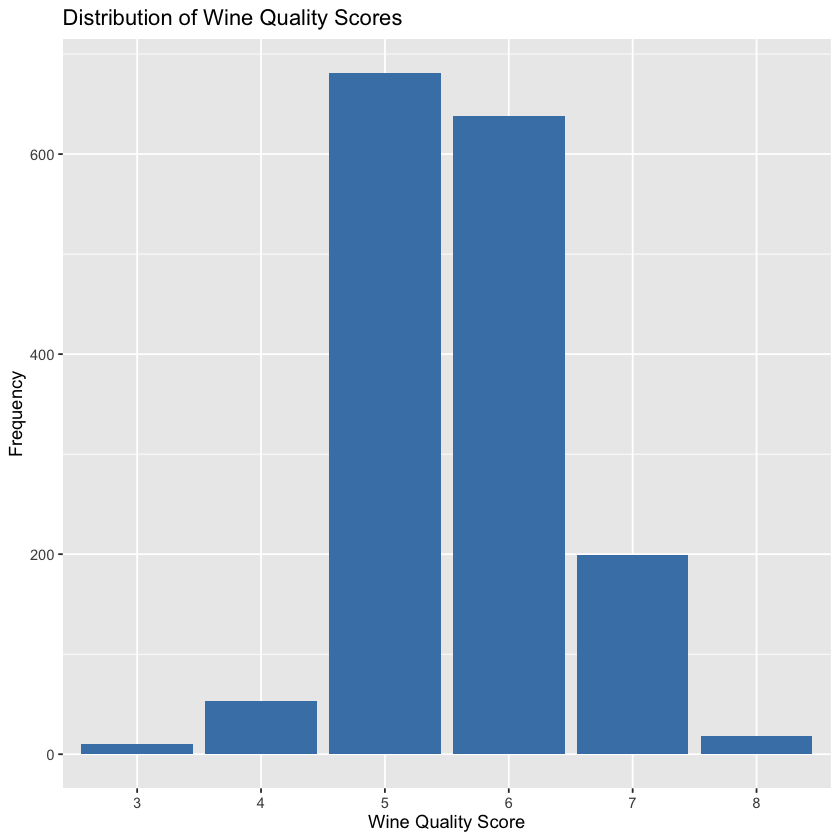

In [7]:
wine |>
  count(quality) |>
  mutate(percentage = round(n / sum(n) * 100, 2))

ggplot(wine, aes(x = factor(quality))) +
  geom_bar(fill = "steelblue") +
  labs(title = "Distribution of Wine Quality Scores",
    x = "Wine Quality Score",
    y = "Frequency")

### Distribution of Input Variables (Wine Characteristics)

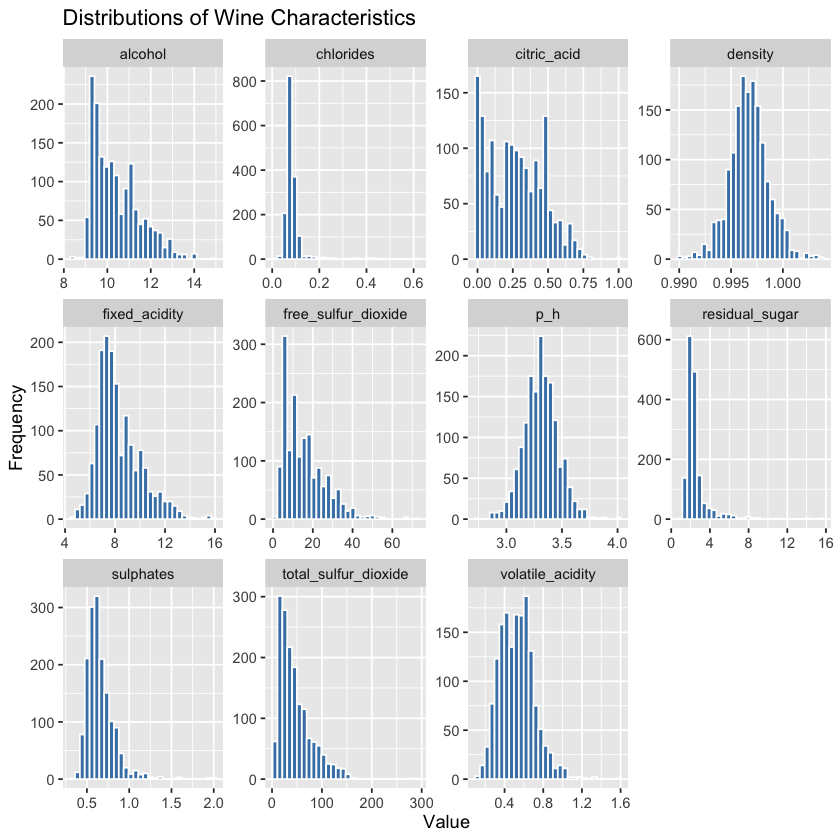

In [8]:
wine |>
  select(-quality) |>
  pivot_longer(cols = everything(),
    names_to = "variable",
    values_to = "value") |>
  ggplot(aes(x = value)) +
  geom_histogram(bins = 30,
    fill = "steelblue",
    color = "white") +
  facet_wrap(~ variable, scales = "free") +
  labs(title = "Distributions of Wine Characteristics",
    x = "Value",
    y = "Frequency") 

### Examining Some Selected Correlation Coeffecients (Pearson)

In [12]:
#Correlation between alcohol and quality
cor(wine$alcohol, wine$quality)

#Correlation between volatile acidity and quality
cor(wine$volatile_acidity, wine$quality)

#Correlation between sulphates and quality
cor(wine$sulphates, wine$quality)

[1] 0.4761663

[1] -0.3905578

[1] 0.2513971

### Creating a Correlation Plot/ HeatMap for all Wine Characteristics

Updating HTML index of packages in '.Library'

Making 'packages.html' ...
 done



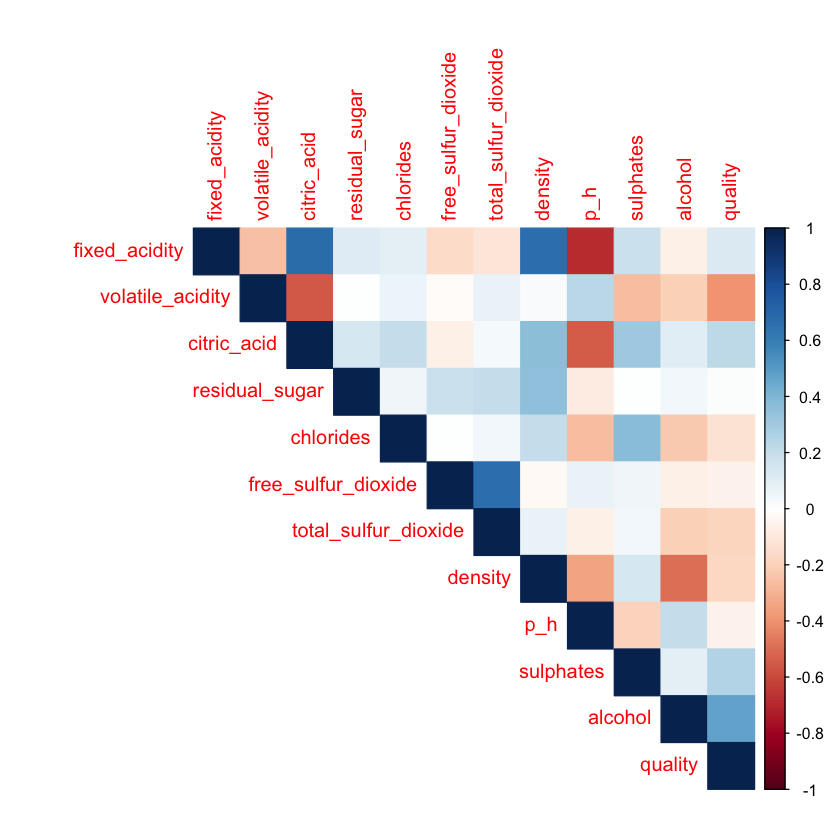

In [13]:
install.packages("corrplot")   
library(corrplot)

cor_matrix <- cor(wine)

corrplot(cor_matrix,
         method = "color",
         type = "upper")

## Formal Data Analysis : Two-Sample t-test

We divided the wines into two groups based on their quality scores: lower-rated wines (quality $\le$ 5) and higher-rated wines (quality $\ge$ 6). This division allows us to compare mean alcohol content between two independent groups while retaining all 1,599 observations. However, this cutoff is an analytical choice rather than an established quality standard.

In [14]:
# create quality groups
wine <- wine |>
    mutate(
        quality_group = if_else(
            quality >= 6,
            "Higher-rated",
            "Lower-rated"
        )
    )

# check group sizes
table(wine$quality_group)


Higher-rated  Lower-rated 
         855          744 

In [15]:
# summary statistics by quality group
wine |>
  group_by(quality_group) |>
  summarise(
    n = n(),
    mean_alcohol = mean(alcohol),
    sd_alcohol = sd(alcohol),
    median_alcohol = median(alcohol)
  )

quality_group,n,mean_alcohol,sd_alcohol,median_alcohol
<chr>,<int>,<dbl>,<dbl>,<dbl>
Higher-rated,855,10.855029,1.1061093,10.8
Lower-rated,744,9.926478,0.7580065,9.7


### Hypothesis

We use a two-sided Welch two-sample t-test to determine whether the mean alcohol content differs between higher-rated and lower-rated red wines.

- $H_0$: $\mu_H$ = $\mu_L$
- $H_A$: $\mu_H$ $\ne$ $\mu_L$

where $\mu_H$ and $\mu_L$ represent the population mean alcohol contents of higher-rated and lower-rated wines, respectively.

Significance level: $\alpha$ = 0.05.


### Basic Idea and Advantages

Welch's two-sample t-test compares the means of two independent groups to determine whether there is a statistically significant difference. It considers the difference between the sample means relative to its standard error. One advantage of this method is that it does not require equal population variances, making it suitable when the two groups have different variabilities. It also provides a confidence interval for the difference in population means.

In [16]:
# two-sample t-test
t_test_result <- t.test(
  alcohol ~ quality_group,
  data = wine,
  alternative = "two.sided",
  var.equal = FALSE,
  conf.level = 0.95
)

t_test_result


	Welch Two Sample t-test

data:  alcohol by quality_group
t = 19.782, df = 1516.8, p-value < 2.2e-16
alternative hypothesis: true difference in means between group Higher-rated and group Lower-rated is not equal to 0
95 percent confidence interval:
 0.836479 1.020622
sample estimates:
mean in group Higher-rated  mean in group Lower-rated 
                 10.855029                   9.926478 


### Two-Sample t-Test

A two-sample t-test was conducted to compare mean alcohol content between higher-rated wines (quality $\ge$ 6) and lower-rated wines (quality $\le$ 5). Welch's test was chosen because it does not require equal population variances, and the two groups had different sample standard deviations (1.106 and 0.758, respectively).

The mean alcohol content was 10.86% for higher-rated wines (n = 855) and 9.93% for lower-rated wines (n = 744). The test showed a statistically significant difference between the two groups, t(1516.8) = 19.78, p < 0.001. The estimated mean difference was 0.93 percentage points, with a 95% confidence interval of [0.84, 1.02].

Therefore, we reject the null hypothesis of equal population means at the 5% significance level. Higher-rated wines had significantly greater mean alcohol content than lower-rated wines. However, this finding does not establish a causal relationship between alcohol content and wine quality.

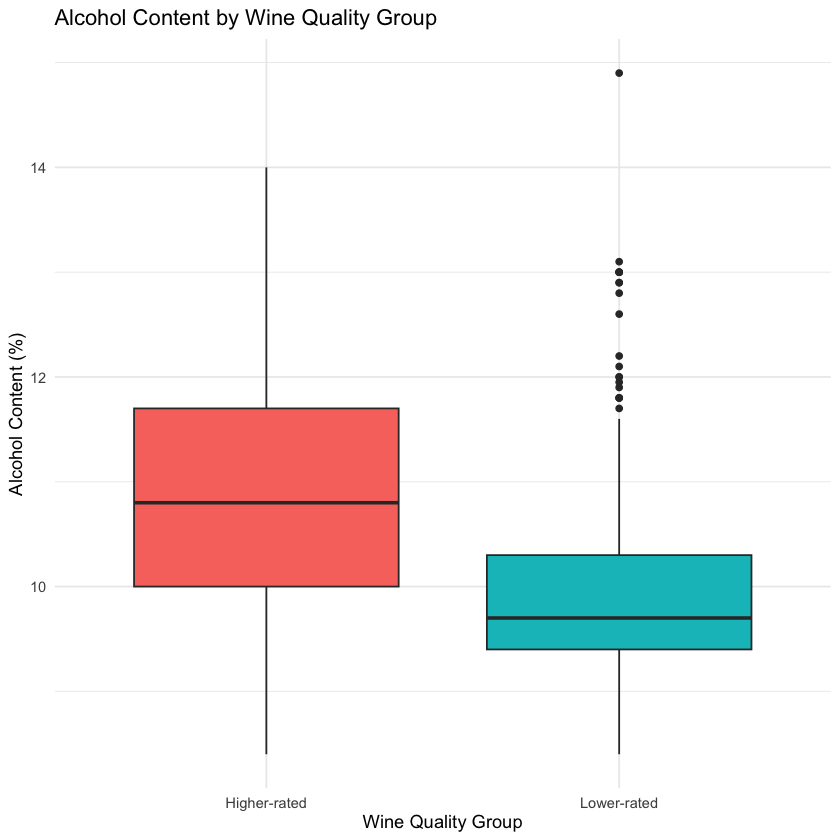

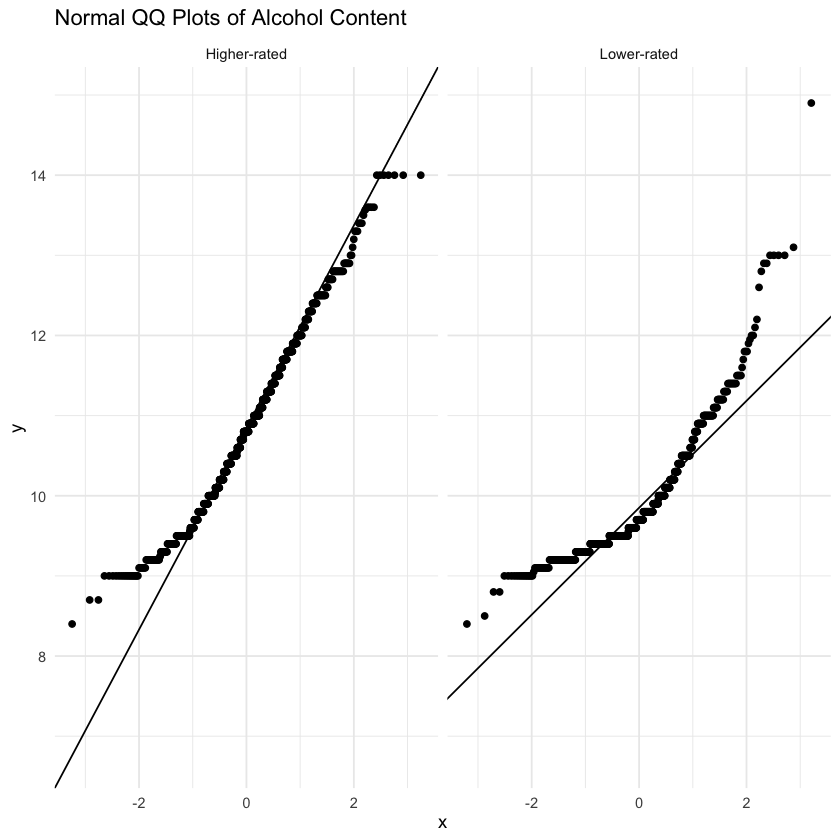

In [18]:
# boxplot: check differences and outliers
ggplot(wine, aes(x = quality_group, y = alcohol,
                 fill = quality_group)) +
  geom_boxplot() +
  labs(
    title = "Alcohol Content by Wine Quality Group",
    x = "Wine Quality Group",
    y = "Alcohol Content (%)"
  ) +
  theme_minimal() +
  theme(legend.position = "none")

# QQ plots: assess normality within each group
ggplot(wine, aes(sample = alcohol)) +
  stat_qq() +
  stat_qq_line() +
  facet_wrap(~ quality_group) +
  labs(
    title = "Normal QQ Plots of Alcohol Content"
  ) +
  theme_minimal()

### Assumptions and Limitations of the Welch Two-Sample t-Test

The boxplots and normal QQ plots suggest that the alcohol content distributions are not perfectly normal, especially for the lower-rated group, which shows right skewness and several outliers. However, both groups have large sample sizes (855 and 744), so the Central Limit Theorem supports the approximate normality of the sampling distribution of the difference in sample means.

We used Welch's two-sample t-test because it does not require equal population variances. However, the presence of outliers may affect the sample means. In addition, dividing quality scores into two groups results in some loss of information, since differences in quality scores within each group are not considered.

Since the dataset is observational and the sampling process is not fully documented, the independence and representativeness of the observations cannot be guaranteed. Therefore, the results should be interpreted with these limitations in mind.